# MRI Brain Tumor Detection using CNN


In [ ]:
import os
import glob
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))



TensorFlow version: 2.21.0
Available GPUs: []


In [ ]:
import zipfile

zip_path = "/content/archive.zip"
extract_path = "./data"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(f"Extracted {zip_path} to {extract_path}")
# Let's verify the extracted directory structure
import os
if os.path.exists(extract_path):
    print("Contents of extraction folder:", os.listdir(extract_path))


Extracted /content/archive.zip to ./data
Contents of extraction folder: ['yes', 'no']


## 2. Load and preprocess the MRI images


In [ ]:
# Downloads the public dataset automatically.
dataset_path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

train_dir = os.path.join(dataset_path, "Training")
test_dir = os.path.join(dataset_path, "Testing")

print("Dataset location:", dataset_path)
print("Training folder exists:", os.path.exists(train_dir))
print("Testing folder exists:", os.path.exists(test_dir))

if not os.path.isdir(train_dir) or not os.path.isdir(test_dir):
    raise FileNotFoundError("Could not find Training/ and Testing/ inside the downloaded dataset.")

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Dataset location: /kaggle/input/brain-tumor-mri-dataset
Training folder exists: True
Testing folder exists: True


In [ ]:
DATA_DIR = "./data"
IMAGE_SIZE = (128, 128)

def load_images(folder, label):
    images, labels = [], []
    # The dataset contains mixed extensions: .jpg, .jpeg, .png, .JPG, .jpeg, etc.
    extensions = ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]
    paths = []
    for ext in extensions:
        paths.extend(glob.glob(os.path.join(DATA_DIR, folder, ext)))

    paths = sorted(list(set(paths)))

    for path in paths:
        image = cv2.imread(path)
        if image is None:
            print("Could not read:", path)
            continue

        image = cv2.resize(image, IMAGE_SIZE)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        images.append(image)
        labels.append(label)

    return images, labels

tumor_images, tumor_labels = load_images("yes", 1)
healthy_images, healthy_labels = load_images("no", 0)

X = np.array(tumor_images + healthy_images, dtype=np.float32)
y = np.array(tumor_labels + healthy_labels, dtype=np.float32)

if len(X) == 0:
    raise ValueError("No images found. Check DATA_DIR and the yes/no folders.")

X /= 255.0

print("Images shape:", X.shape)   # (number_of_images, 128, 128, 3)
print("Labels shape:", y.shape)
print("Tumor images:", len(tumor_images))
print("Healthy images:", len(healthy_images))

Images shape: (253, 128, 128, 3)
Labels shape: (253,)
Tumor images: 155
Healthy images: 98


## 3. Visualize sample images
Inspecting examples helps confirm that the files and labels were loaded correctly.

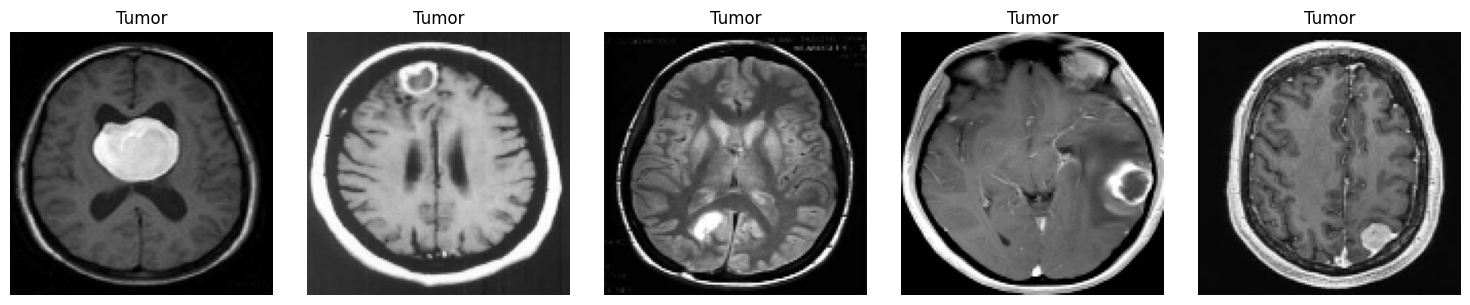

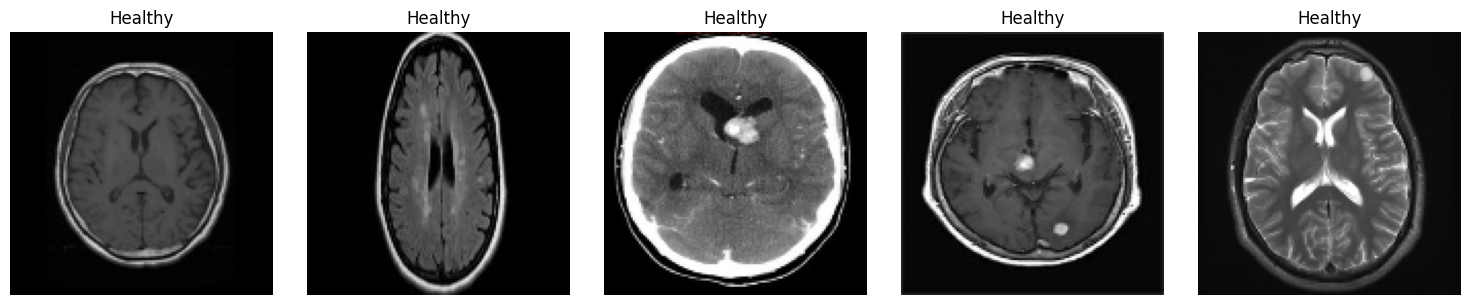

In [ ]:
def show_samples(images, title, count=5):
    count = min(count, len(images))
    if count == 0:
        print("No images available for", title)
        return

    indices = np.random.choice(len(images), count, replace=False)
    plt.figure(figsize=(3 * count, 3))
    for position, index in enumerate(indices, start=1):
        plt.subplot(1, count, position)
        plt.imshow(images[index])
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(tumor_images, "Tumor")
show_samples(healthy_images, "Healthy")

## 4. Split data into training and validation sets


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Training images:", X_train.shape[0])
print("Validation images:", X_val.shape[0])
print("Training class counts (healthy, tumor):",
      np.bincount(y_train.astype(int)))
print("Validation class counts (healthy, tumor):",
      np.bincount(y_val.astype(int)))

Training images: 202
Validation images: 51
Training class counts (healthy, tumor): [ 78 124]
Validation class counts (healthy, tumor): [20 31]


## 5. Build the CNN model using Keras



In [ ]:
def build_cnn():
    model = keras.Sequential([
        layers.Input(shape=(128, 128, 3)),

        layers.Conv2D(6, kernel_size=5, padding="valid"),
        layers.Activation("tanh"),
        layers.AveragePooling2D(pool_size=2, strides=5),

        layers.Conv2D(16, kernel_size=5, padding="valid"),
        layers.Activation("tanh"),
        layers.AveragePooling2D(pool_size=2, strides=5),

        layers.Flatten(),

        layers.Dense(120, activation="tanh"),
        layers.Dense(84, activation="tanh"),
        layers.Dense(1, activation="sigmoid")
    ])
    return model

model = build_cnn()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 124, 124, 6)    │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 124, 124, 6)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 25, 25, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 21, 21, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 21, 21, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 4, 4, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        30,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,961 (171.72 KB)

 Trainable params: 43,961 (171.72 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Compile the model


In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

## 7. Train the model


In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 310ms/step - accuracy: 0.6089 - loss: 0.6690 - val_accuracy: 0.6078 - val_loss: 0.6561
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 419ms/step - accuracy: 0.6139 - loss: 0.6503 - val_accuracy: 0.6078 - val_loss: 0.6503
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 340ms/step - accuracy: 0.6139 - loss: 0.6431 - val_accuracy: 0.6078 - val_loss: 0.6433
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 262ms/step - accuracy: 0.6139 - loss: 0.6348 - val_accuracy: 0.6078 - val_loss: 0.6344
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 301ms/step - accuracy: 0.6139 - loss: 0.6266 - val_accuracy: 0.6275 - val_loss: 0.6262
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 344ms/step - accuracy: 0.6139 - loss: 0.6195 - val_accuracy: 0.6471 - val_loss: 0.6190
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 348ms/step - accuracy: 0.6287 - loss: 0.6128 - val_accuracy: 0.6471 - val_loss: 0.6123
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 511ms/step - accuracy: 0.6337 - loss: 0.6060 - val_accuracy: 0.6471 - v

## 8. Plot training and validation loss

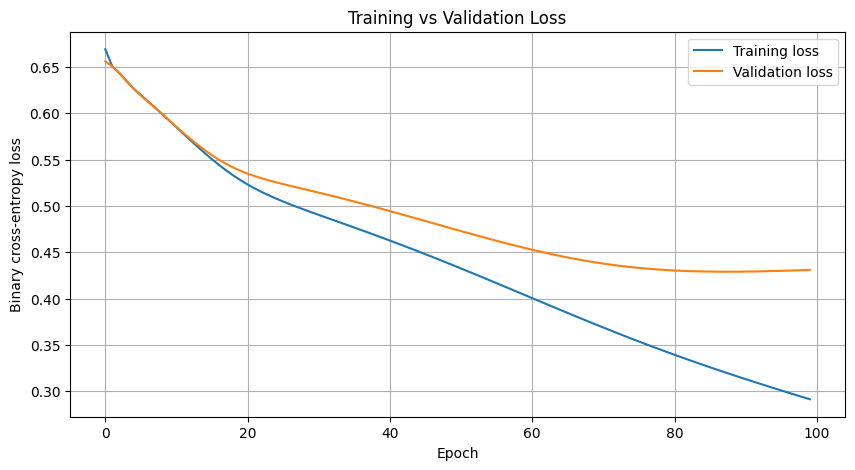

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## 9. Evaluate the model


In [ ]:
y_prob = model.predict(X_val).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Validation accuracy:", accuracy_score(y_val, y_pred))
print("\nClassification report:")
print(classification_report(
    y_val, y_pred,
    labels=[0, 1],
    target_names=["Healthy", "Tumor"],
    zero_division=0
))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step
Validation accuracy: 0.803921568627451

Classification report:
              precision    recall  f1-score   support

     Healthy       0.81      0.65      0.72        20
       Tumor       0.80      0.90      0.85        31

    accuracy                           0.80        51
   macro avg       0.81      0.78      0.79        51
weighted avg       0.80      0.80      0.80        51



## 10. Confusion matrix


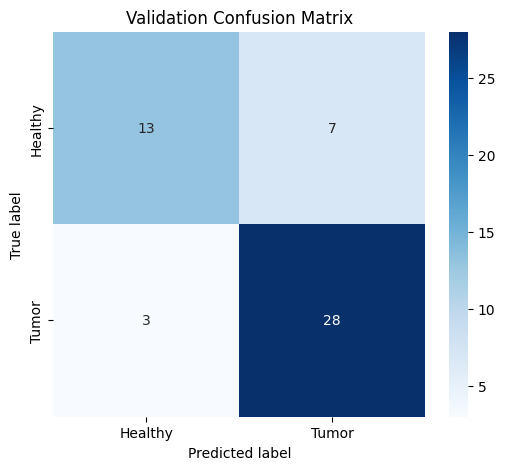

In [ ]:
cm = confusion_matrix(y_val, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Healthy", "Tumor"],
    yticklabels=["Healthy", "Tumor"]
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Validation Confusion Matrix")
plt.show()

## 11. Visualize CNN feature maps


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step


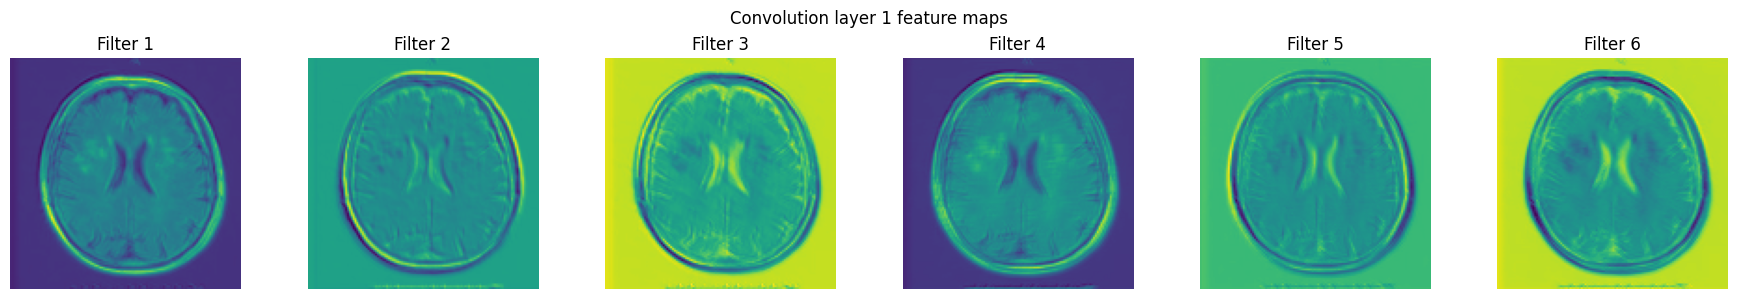

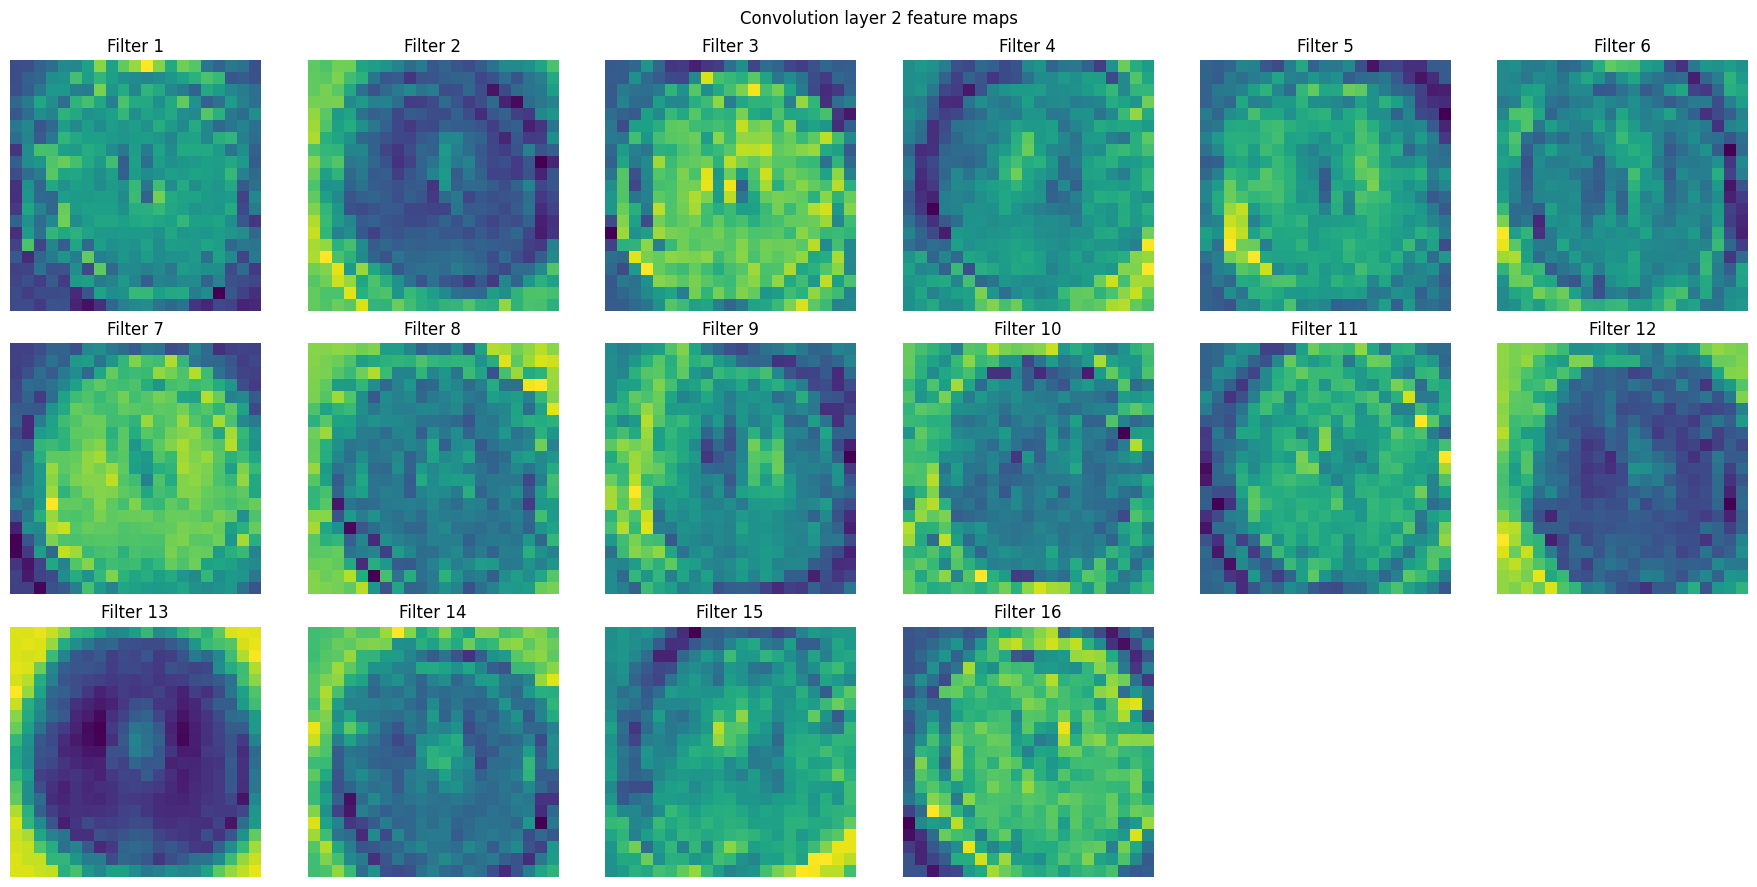

In [ ]:
# Select one validation image and add a batch dimension.
sample_image = X_val[0]
input_batch = np.expand_dims(sample_image, axis=0)

# Create a symbolic input with the model's input shape to construct the functional mapping
symbolic_input = keras.Input(shape=(128, 128, 3))

# To get intermediate layer outputs safely on a Sequential model, we can trace it
layer_outputs = {}
x = symbolic_input
for layer in model.layers:
    x = layer(x)
    if isinstance(layer, layers.Conv2D):
        layer_outputs[layer.name] = x

# Create the functional feature extraction model
feature_model = keras.Model(inputs=symbolic_input, outputs=list(layer_outputs.values()))

# Predict to get the feature maps
feature_maps = feature_model.predict(input_batch)
if not isinstance(feature_maps, list):
    feature_maps = [feature_maps]

for layer_number, feature_map in enumerate(feature_maps, start=1):
    number_of_filters = feature_map.shape[-1]
    columns = min(6, number_of_filters)
    rows = int(np.ceil(number_of_filters / columns))

    plt.figure(figsize=(3 * columns, 3 * rows))
    for filter_index in range(number_of_filters):
        plt.subplot(rows, columns, filter_index + 1)
        plt.imshow(feature_map[0, :, :, filter_index], cmap="viridis")
        plt.title(f"Filter {filter_index + 1}")
        plt.axis("off")

    plt.suptitle(f"Convolution layer {layer_number} feature maps")
    plt.tight_layout()
    plt.show()

## 12. Predict on a single MRI image

In [ ]:
def predict_mri(image_path, trained_model=model):
    image = cv2.imread(image_path)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {image_path}")

    image = cv2.resize(image, IMAGE_SIZE)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = image.astype(np.float32) / 255.0

    probability = float(
        trained_model.predict(np.expand_dims(image, axis=0), verbose=0)[0][0]
    )
    prediction = "Tumor" if probability >= 0.5 else "Healthy"

    plt.imshow(image)
    plt.title(f"Prediction: {prediction} (score: {probability:.3f})")
    plt.axis("off")
    plt.show()

    return prediction, probability

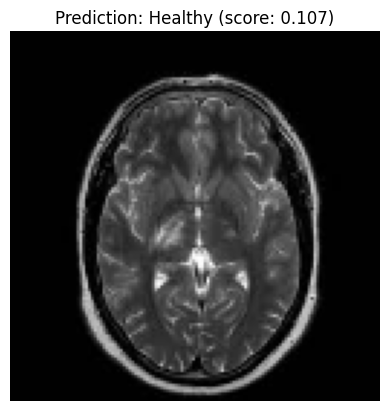

('Healthy', 0.10691580921411514)

In [ ]:
predict_mri("/content/data/no/35 no.jpg",model)

In [ ]:
train_loss, train_accuracy = model.evaluate(X_train, y_train, verbose=0)
val_loss, val_accuracy = model.evaluate(X_val, y_val, verbose=0)

print(f"Training Accuracy: {train_accuracy * 100:.2f}%")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

Training Accuracy: 88.61%
Validation Accuracy: 80.39%
